# 04 Training

How every network in the study was trained: the recipe, the loss, the regularization, and what the
training curves show. Nothing is retrained here. The curves and timings come from the run records the
Kaggle notebooks wrote (`results/`), and the settings come from `configs/study.yaml`, which
`tests/test_config.py` checks against the code that ran.

In [1]:
import csv
import json
import os
import sys

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('../src'))
import local

CFG = local.config()
COL = {'resgru': '#2a78d6', 'afnov4': '#eb6834', 'fmgwaclu': '#1baf7a', 'convlstm': '#eda100', 'patchafno': '#e87ba4'}
NAME = {'resgru': 'ResGRU-UNet', 'afnov4': 'AFNO V4', 'fmgwaclu': 'FMG-WACLU', 'convlstm': 'ConvLSTM', 'patchafno': 'patch AFNO'}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.color': '#e4e3df', 'axes.spines.top': False, 'axes.spines.right': False})

## 1. The recipe

Every network used the same recipe: AFNO V4's phase A, unchanged. It was tuned for AFNO V4, so if
anything it favours that network.

In [2]:
t = CFG['training']
rows = [('epochs', t['epochs']), ('optimizer', f"AdamW, lr {t['learning_rate']}, weight decay {t['weight_decay']}"),
        ('schedule', 'one-cycle'), ('effective batch', t['batch']), ('weight averaging', f"EMA, decay {t['ema_decay']}"),
        ('mixed precision', 'yes'), ('gradient clipping', 1.0), ('selection', 'best epoch by the validation score'),
        ('loss weights', t['loss']), ('episode weight (Huber term)', t['episode_weight']),
        ('lead-hour weights', f"linear {t['horizon_weights'][0]} to {t['horizon_weights'][1]} (Huber and global SMAPE terms)"),
        ('seed (round one)', t['seed'])]
for k, v in rows:
    print(f'{k:30s} {v}')

epochs                         16
optimizer                      AdamW, lr 0.00025, weight decay 0.0001
schedule                       one-cycle
effective batch                4
weight averaging               EMA, decay 0.999
mixed precision                yes
gradient clipping              1.0
selection                      best epoch by the validation score
loss weights                   {'huber': 0.4, 'gsmape': 0.25, 'esmape': 0.15, 'ecorr': 0.2}
episode weight (Huber term)    6.0
lead-hour weights              linear 0.7 to 1.3 (Huber and global SMAPE terms)
seed (round one)               42


## 2. The loss

The loss is matched to the benchmark score:

$$\mathcal{L} = 0.40\,\mathcal{H}_{\log} + 0.25\,G + 0.15\,E + 0.20\,(1-\rho)$$

$\mathcal{H}_{\log}$ is a Huber loss on $\log(1+y)$ with episode cells weighted by 6; $G$ and $E$ are
global and episode SMAPE; $\rho$ is the Pearson correlation on episode cells. Errors grow with lead
time while the score weights every hour equally, so lead hours are weighted from 0.7 to 1.3 in the
Huber and global terms. Below are the weights the code uses (normalized to mean 1).

lead-hour weights: [0.7  0.74 0.78 0.82 0.86 0.9  0.94 0.98 1.02 1.06 1.1  1.14 1.18 1.22
 1.26 1.3 ]


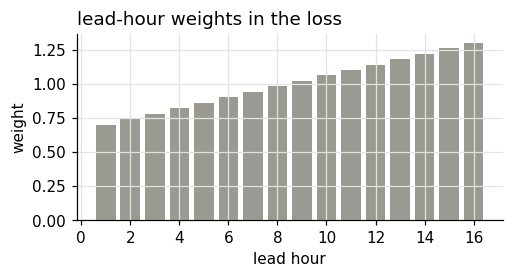

In [3]:
w = np.linspace(*t['horizon_weights'], 16)
w = w / w.mean()
print('lead-hour weights:', np.round(w, 3))

fig, ax = plt.subplots(figsize=(5, 2.2))
ax.bar(np.arange(1, 17), w, color='#9a9a93')
ax.set_xlabel('lead hour'); ax.set_ylabel('weight'); ax.set_title('lead-hour weights in the loss', loc='left')
plt.show()

## 3. Regularization

The networks have 3 to 19 million parameters but see only 2,257 training windows from four months.

| Control | Where | Why |
|:--|:--|:--|
| channel dropout 0.1 | every conv block of ResGRU-UNet and AFNO V4, AFNO V4's MLPs | discourage co-adapted feature maps |
| dropout 0.25, stochastic depth 0.15 | ConvLSTM | its original settings |
| weight decay 1e-4 (AdamW) | all | keeps weights small |
| EMA of the weights, 0.999 | all; the EMA weights are evaluated | smoother, better-generalizing weights |
| best epoch by validation score | all | acts as early stopping |
| gradient clipping 1.0, input clipping at 10, std floors | all | rare extreme values |
| seed ensembles | finalists | removes part of the run-to-run variance |

## 4. Training curves of every run

Each Kaggle run logged one row per epoch. Round one trained five networks on seed 42; the 5-seed
extension added seeds 1 to 3 of the finalists (seed 1337 came from the final round); the ablations
added four single-change variants.

In [4]:
def read_log(folder):
    runs = {}
    for r in csv.DictReader(open(local.result(folder, 'train_log.csv'))):
        runs.setdefault(r['phase'].replace('_phaseA', ''), []).append(r)
    return runs


runs = {}
for folder in ('resgru', 'fmgwaclu', 'convlstm', 'patchafno', 'final', 'seeds_resgru', 'seeds_afnov4', 'ablations_a', 'ablations_b'):
    runs.update(read_log(folder))
print(len(runs), 'runs with per-epoch logs:', ', '.join(sorted(runs)))

15 runs with per-epoch logs: afnov4_allskip_s42, afnov4_nosparse_s42, afnov4_pad_s42, afnov4_s1, afnov4_s2, afnov4_s3, convlstm_s42, fmgwaclu_s42, patchafno_s42, resgru_norec_s42, resgru_s1, resgru_s1337, resgru_s2, resgru_s3, resgru_s42


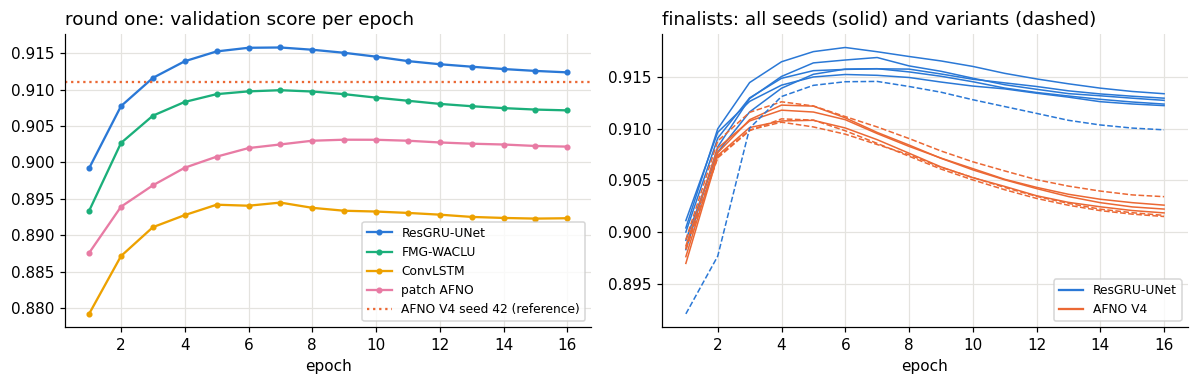

In [5]:
def family(name):
    return next(f for f in ('resgru', 'afnov4', 'fmgwaclu', 'convlstm', 'patchafno') if name.startswith(f))


fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for name in ('resgru_s42', 'fmgwaclu_s42', 'convlstm_s42', 'patchafno_s42'):
    rows = runs[name]
    f = family(name)
    ax[0].plot([int(r['epoch']) for r in rows], [float(r['val_score']) for r in rows], color=COL[f], label=NAME[f], marker='o', ms=3)
for name, rows in runs.items():
    f = family(name)
    if f in ('resgru', 'afnov4'):
        ax[1].plot([int(r['epoch']) for r in rows], [float(r['val_score']) for r in rows], color=COL[f],
                   ls='--' if name.count('_') > 1 else '-', lw=1.0)
ax[0].axhline(0.9110, color=COL['afnov4'], ls=':', label='AFNO V4 seed 42 (reference)')
ax[0].set_title('round one: validation score per epoch', loc='left'); ax[0].legend(fontsize=8); ax[0].set_xlabel('epoch')
ax[1].set_title('finalists: all seeds (solid) and variants (dashed)', loc='left'); ax[1].set_xlabel('epoch')
ax[1].legend(handles=[plt.Line2D([], [], color=COL['resgru'], label=NAME['resgru']), plt.Line2D([], [], color=COL['afnov4'], label=NAME['afnov4'])], fontsize=8)
plt.tight_layout(); plt.show()

AFNO V4's seeds 42 and 1337 were trained by V4's own script and have no log in this format, so the
AFNO curves on the right are seeds 1 to 3 and the three AFNO variants.

## 5. Best epoch, time and memory

In [6]:
def summaries():
    out = []
    for folder in ('resgru', 'fmgwaclu', 'convlstm', 'patchafno', 'final'):
        out.append(local.load_json(folder, 'summary.json'))
    for folder in ('seeds_resgru', 'seeds_afnov4'):
        for s in (1, 2, 3):
            out.append(local.load_json(folder, f'summary_s{s}.json'))
    for folder, names in (('ablations_a', ('afnov4_allskip', 'afnov4_nosparse')), ('ablations_b', ('afnov4_pad', 'resgru_norec'))):
        for n in names:
            out.append(local.load_json(folder, f'summary_{n}.json'))
    return out


print(f"{'run':24s} {'params':>10s} {'best ep':>8s} {'val score':>10s} {'s/epoch':>8s} {'train min':>10s}")
for s in summaries():
    best = s.get('best', {})
    print(f"{s['backbone'] + ' seed ' + str(s['seed']):24s} {s.get('params', 0):>10,} {str(best.get('epoch', '')):>8s} "
          f"{best.get('score', float('nan')):>10.5f} {s.get('secs_per_epoch', float('nan')):>8.1f} {s.get('train_minutes', float('nan')):>10.1f}")

run                          params  best ep  val score  s/epoch  train min
resgru seed 42            7,122,113        7    0.91579    189.3       50.6
fmgwaclu seed 42          3,454,645        7    0.90992    529.6      141.3
convlstm seed 42         19,001,840        7    0.89448     69.4       18.6
patchafno seed 42         5,708,800        9    0.90312     55.5       14.9
resgru seed 1337          7,122,113        6    0.91523    186.2       49.7
resgru seed 1             7,122,113        7    0.91687    191.4       51.1
resgru seed 2             7,122,113        6    0.91784    190.4       50.8
resgru seed 3             7,122,113        7    0.91578    190.5       50.8
afnov4 seed 1             6,980,033        4    0.91178    337.8       90.2
afnov4 seed 2             6,980,033        4    0.91227    338.1       90.2
afnov4 seed 3             6,980,033        5    0.91080    337.9       90.1
afnov4_allskip seed 42    7,668,161        4    0.91259    344.5       91.9
afnov4_nospa

## 6. A generalization gap

Plotting validation loss against training loss removes the effect of training speed. At the same
training loss, AFNO V4 has a higher validation loss than ResGRU-UNet in every logged run: it fits the
training months more closely and does worse on the held-out months. This is exploratory: it was
not part of the pre-registered ablations.

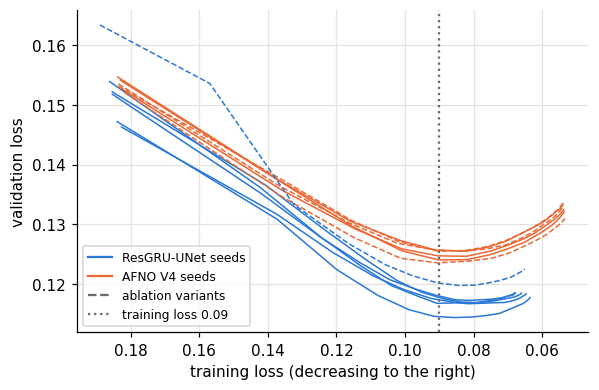

validation loss at training loss 0.09: AFNO V4 seeds [0.1247 0.1241 0.1257], ResGRU-UNet seeds [0.1178 0.1174 0.1168 0.1146 0.118 ]
AFNO V4 is 6.8% higher on average (seeds only)


In [7]:
def val_loss_at(rows, target=0.09):
    for a, b in zip(rows, rows[1:]):
        ta, tb = float(a['tr_loss']), float(b['tr_loss'])
        if ta >= target >= tb:
            w = (ta - target) / (ta - tb)
            return float(a['val_loss']) + w * (float(b['val_loss']) - float(a['val_loss']))
    return float('nan')


fig, ax = plt.subplots(figsize=(6, 3.8))
gap = {'afnov4': [], 'resgru': []}
for name, rows in runs.items():
    f = family(name)
    if f not in gap:
        continue
    ax.plot([float(r['tr_loss']) for r in rows], [float(r['val_loss']) for r in rows], color=COL[f],
            ls='--' if name.count('_') > 1 else '-', lw=1.0)
    if name.count('_') == 1:
        gap[f].append(val_loss_at(rows))
ax.invert_xaxis(); ax.axvline(0.09, color='#6b6b66', ls=':')
ax.legend(handles=[plt.Line2D([], [], color=COL['resgru'], label=NAME['resgru'] + ' seeds'), plt.Line2D([], [], color=COL['afnov4'], label=NAME['afnov4'] + ' seeds'),
                   plt.Line2D([], [], color='#6b6b66', ls='--', label='ablation variants'), plt.Line2D([], [], color='#6b6b66', ls=':', label='training loss 0.09')], fontsize=8)
ax.set_xlabel('training loss (decreasing to the right)'); ax.set_ylabel('validation loss')
plt.show()
a, r = np.mean(gap['afnov4']), np.mean(gap['resgru'])
print(f'validation loss at training loss 0.09: AFNO V4 seeds {np.round(gap["afnov4"], 4)}, ResGRU-UNet seeds {np.round(gap["resgru"], 4)}')
print(f'AFNO V4 is {100 * (a / r - 1):.1f}% higher on average (seeds only)')